In [1]:
import numpy as np
import os
import time
import scipy
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from matplotlib import cm

#Want to use version of Tensorflow > 2.0
print('Using Tensorflow version %s' % tf.__version__)


Using Tensorflow version 2.10.1


In [2]:
def writeFile(new_df, fileName):
    new_df.to_csv(fileName, sep=' ', index=False)#, header=None)

In [3]:
def find_intercept(x1,y1,x2,y2):
    # 2. Create continuous functions by interpolating the arrays
    f1 = scipy.interpolate.interp1d(x1, y1, kind='quadratic')
    f2 = scipy.interpolate.interp1d(x2, y2, kind='quadratic')

    # 3. Define the difference function (equals 0 at the intersection)
    def difference(x_val):
        return f1(x_val) - f2(x_val)
    
    # 4. Provide an initial guess near the crossing point and solve
    initial_guess = 0.5
    x_intercept = scipy.optimize.fsolve(difference, initial_guess)[0]
    y_intercept = f1(x_intercept)

    return x_intercept, y_intercept

In [4]:
#columns for input with all FFA parameters and output with only fixfield format particle data

fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]

fixfield_phase_space_headers =  ["x [m]", "y [m]", "z [m]", "ux []", "uy []", "uz []"]

fixfield_para_headers =  ["rmin [m]", "rmax [m]", "zmax [m]", "Cell opening angle [deg]", "r0 [m]", "k_val",
                        "C1", "lambda0",  "mag0 B0 [T]",  "mag0 cent_theta[deg]", "mag0 length_theta[deg]", 
                        "mag1 B0 [T]",  "mag1 cent_theta[deg]", "mag1 length_theta[deg]", "mag2 B0 [T]",  "mag2 cent_theta[deg]", "mag2 length_theta[deg]"]

ML_sample_headers =  ["rmin [m]", "rmax [m]", "zmax [m]", "Cell opening angle [deg]", "r0 [m]", "k_val",
                        "C1", "lambda0",  "mag0 B0 [T]",  "mag0 cent_theta[deg]", "mag0 length_theta[deg]", 
                        "mag1 B0 [T]",  "mag1 cent_theta[deg]", "mag1 length_theta[deg]", "mag2 B0 [T]",  "mag2 cent_theta[deg]", "mag2 length_theta[deg]", 
                        "m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]

print("input col num : "+str(len(ML_sample_headers))+", output col num : "+str(len(fixfield_headers)))
print(len(fixfield_para_headers))

input col num : 26, output col num : 9
17


In [5]:
#read generated sample data with pandas read_csv

FFA_ML_input = "ML_FFA_sample/ML_input_merged.dat"
FFA_ML_output = "ML_FFA_sample/ML_output_merged.dat"

input_df = pd.DataFrame()
input_df = pd.read_csv(FFA_ML_input, sep = "\s+", skiprows=1, names=ML_sample_headers) #input for ML contains all info of FFA magnets
input_para_df = input_df[fixfield_para_headers]
input_phase_space_df = input_df[fixfield_headers]
input_np_lst = input_df.to_numpy()
input_para_np_lst = input_para_df.to_numpy()
input_phase_space_np_lst = input_phase_space_df.to_numpy()

output_df = pd.DataFrame()
output_df = pd.read_csv(FFA_ML_output, sep = "\s+", skiprows=1, names=fixfield_headers) #output for ML contains only particle data in form of fixfield
output_df = output_df[fixfield_phase_space_headers]
output_np_lst = output_df.to_numpy()
output_lost_lst = np.ones(len(output_df["x [m]"])) #list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

print("number of particles : "+str(len(output_df["x [m]"])))

#============================================================================================================
#put the read data into np array

total_part_num = len(output_df["x [m]"])
sample_part_num = int(total_part_num/2)#assgin half of sample for train and other half for validation
input_col_num = len(ML_sample_headers)
input_para_col_num = len(fixfield_para_headers)
input_phase_space_col_num = len(fixfield_headers)

FFA_parameter_len = len(fixfield_para_headers)
output_col_num = len(fixfield_phase_space_headers)

input_train = np.zeros(sample_part_num*input_col_num).reshape((sample_part_num,input_col_num)) #training data
input_para_train = np.zeros(sample_part_num*input_para_col_num).reshape((sample_part_num,input_para_col_num)) #training data
input_phase_space_train = np.zeros(sample_part_num*input_phase_space_col_num).reshape((sample_part_num,input_phase_space_col_num)) #training data
output_train = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num))
output_lost_train = np.ones(sample_part_num)#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

input_val = np.zeros(sample_part_num*input_col_num).reshape((sample_part_num,input_col_num)) #validation data
input_para_val = np.zeros(sample_part_num*input_para_col_num).reshape((sample_part_num,input_para_col_num)) #training data
input_phase_space_val = np.zeros(sample_part_num*input_phase_space_col_num).reshape((sample_part_num,input_phase_space_col_num)) #training data
output_val = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num))
output_lost_val = np.ones(sample_part_num)#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

FFA_parameter_norm = 200
Ptot_norm = 1e4
space_norm = 2

#create array for normalizing number in data to -1 ~ 1
input_norm_array = np.ones(input_col_num)
output_norm_array = np.ones(output_col_num)

for i in range(0, FFA_parameter_len):
    input_norm_array[i] = FFA_parameter_norm

for i in range(0, 3):
    input_norm_array[i+2+FFA_parameter_len] = space_norm
    output_norm_array[i] = space_norm

input_norm_array[5+FFA_parameter_len] = Ptot_norm
output_norm_array[3] = 0.04
output_norm_array[5] = 0.04
#output_norm_array[5] = Ptot_norm

lost_count_train = 0
lost_count_val = 0
for i in range(0,sample_part_num):
    input_train[i] = input_np_lst[2*i]
    input_val[i] = input_np_lst[2*i+1]

    input_para_train[i] = input_para_np_lst[2*i]
    input_para_val[i] = input_para_np_lst[2*i+1]

    input_phase_space_train[i] = input_phase_space_np_lst[2*i]
    input_phase_space_val[i] = input_phase_space_np_lst[2*i+1]

    output_train[i] = output_np_lst[2*i]
    output_val[i] = output_np_lst[2*i+1]

    #normalize numbers in array for ML
    
    for j in range(0, input_col_num):
        input_train[i][j] = input_train[i][j]/input_norm_array[j]
        input_val[i][j] = input_val[i][j]/input_norm_array[j]
        
    for j in range(0, output_col_num):
        output_train[i][j] = output_train[i][j]/output_norm_array[j]
        output_val[i][j] = output_val[i][j]/output_norm_array[j]

    if (output_train[i][3]+output_train[i][4]+output_train[i][5])<1e-6:#lost particles have 0 phase space val. So sum of ux,uy,uz is 0 -> lost
        output_lost_train[i] = 0#if particle is lost assign 0
        lost_count_train = lost_count_train + 1

    if (output_val[i][3]+output_val[i][4]+output_val[i][5])<1e-6:
        output_lost_val[i] = 0
        lost_count_val = lost_count_val + 1



print("input_train")
print(input_train)
print("output_train")
print(output_train)
print("output_lost_train")
print(output_lost_train)
print("lost_count_train : "+str(lost_count_train)+", lost_count_val : "+str(lost_count_val))
print(output_np_lst[4])
print(input_norm_array)
print(output_norm_array)
print("train particle num : "+str(len(input_train))+", val particle num : "+str(len(input_val))
      +", input column : "+str(len(input_train[0]))+",  output column : "+str(len(output_train[0])))

number of particles : 281250
input_train
[[ 2.40253821e-01  2.50253821e-01  1.49759656e-03 ...  1.69197941e-02
   9.99783310e-01  1.21265368e-02]
 [ 2.40253821e-01  2.50253821e-01  1.49759656e-03 ...  8.28411856e-04
   9.99943106e-01 -1.06347347e-02]
 [ 2.40253821e-01  2.50253821e-01  1.49759656e-03 ...  1.55089460e-02
   9.99855898e-01 -6.90333703e-03]
 ...
 [ 2.42144475e-01  2.52144475e-01  1.51650310e-03 ... -4.14148101e-03
   9.99800907e-01 -1.95190613e-02]
 [ 2.42144475e-01  2.52144475e-01  1.51650310e-03 ...  1.76774342e-02
   9.99842928e-01 -1.27551834e-03]
 [ 2.42144475e-01  2.52144475e-01  1.51650310e-03 ...  1.60968258e-02
   9.99849309e-01 -6.50006446e-03]]
output_train
[[ 0.23244035 -0.          0.03847184  1.0595765   0.9990271   0.304707  ]
 [ 0.15312935  0.         -0.04602992  1.151067    0.998891   -0.24612373]
 [ 0.23859305  0.         -0.07196175  0.52806     0.9997732   0.06794405]
 ...
 [ 0.4988407   0.         -0.0699574   3.875355    0.9876827  -0.53241   ]
 [ 0.

[]

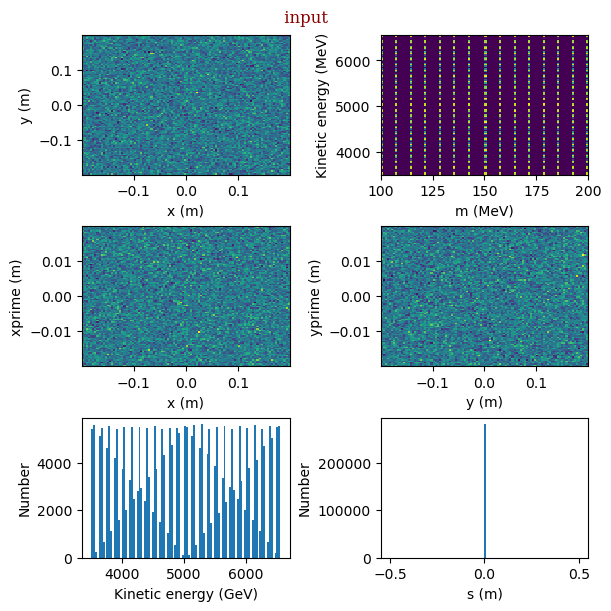

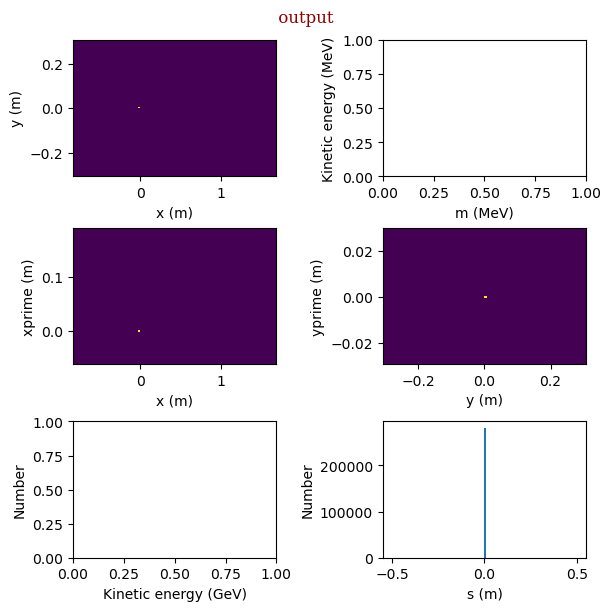

In [6]:
logE = False
font = {'family': 'serif', \
        'color':  'darkred' \
        }

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " input "

fig.suptitle(Ttl, fontdict=font)

#axs[0, 0].set_title('x,y')
axs[0, 0].hist2d(input_df["x [m]"].to_numpy(), input_df["z [m]"].to_numpy(), bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

#axs[0, 1].set_title('delta')

axs[0, 1].hist2d(input_df["m0 [MeV*c^-2]"].to_numpy(), input_df["Ptot [MeV/c]"].to_numpy(), bins=100)#2d hist of energy and r
axs[0, 1].set_xlabel('m (MeV)')
axs[0, 1].set_ylabel('Kinetic energy (MeV)')

#axs[1, 0].set_title('x, xprime')
axs[1, 0].hist2d(input_df["x [m]"].to_numpy(), input_df["ux []"].to_numpy(), bins=100)
axs[1, 0].set_xlabel('x (m)')
axs[1, 0].set_ylabel('xprime (m)')

#axs[1, 1].set_title('y, yprime')
axs[1, 1].hist2d(input_df["z [m]"].to_numpy(), input_df["uz []"].to_numpy(), bins=100)
axs[1, 1].set_xlabel('y (m)')
axs[1, 1].set_ylabel('yprime (m)')

axs[2, 0].hist(input_df["Ptot [MeV/c]"].to_numpy(), 100)
axs[2, 0].set_yscale('linear')
if logE:
    axs[2, 0].set_yscale('log')
axs[2, 0].set_xlabel('Kinetic energy (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].hist(input_df["y [m]"].to_numpy(), 100)
axs[2, 1].set_yscale('linear')
if logE:
    axs[2, 1].set_yscale('log')
axs[2, 1].set_xlabel('s (m)')
axs[2, 1].set_ylabel('Number')

plt.plot()

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " output "

fig.suptitle(Ttl, fontdict=font)

#axs[0, 0].set_title('x,y')
axs[0, 0].hist2d(output_df["x [m]"].to_numpy(), output_df["z [m]"].to_numpy(), bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

#axs[0, 1].set_title('delta')

#axs[0, 1].hist2d(output_df["m0 [MeV*c^-2]"].to_numpy(), output_df["Ptot [MeV/c]"].to_numpy(), bins=100)#2d hist of energy and r
axs[0, 1].set_xlabel('m (MeV)')
axs[0, 1].set_ylabel('Kinetic energy (MeV)')

#axs[1, 0].set_title('x, xprime')
axs[1, 0].hist2d(output_df["x [m]"].to_numpy(), output_df["ux []"].to_numpy(), bins=100)
axs[1, 0].set_xlabel('x (m)')
axs[1, 0].set_ylabel('xprime (m)')

#axs[1, 1].set_title('y, yprime')
axs[1, 1].hist2d(output_df["z [m]"].to_numpy(), output_df["uz []"].to_numpy(), bins=100)
axs[1, 1].set_xlabel('y (m)')
axs[1, 1].set_ylabel('yprime (m)')

#axs[2, 0].hist(output_df["Ptot [MeV/c]"].to_numpy(), 100)
axs[2, 0].set_yscale('linear')
if logE:
    axs[2, 0].set_yscale('log')
axs[2, 0].set_xlabel('Kinetic energy (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].hist(output_df["y [m]"].to_numpy(), 100)
axs[2, 1].set_yscale('linear')
if logE:
    axs[2, 1].set_yscale('log')
axs[2, 1].set_xlabel('s (m)')
axs[2, 1].set_ylabel('Number')

plt.plot()

In [7]:
#create model
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(input_col_num, input_dim=input_col_num),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Dense(192, activation='tanh'),
    tf.keras.layers.Dense(128),#, activation="tanh"
    tf.keras.layers.Dense(64, activation='tanh'),
    tf.keras.layers.LayerNormalization(),
    tf.keras.layers.Dense(output_col_num)#, activation='tanh')
])

In [8]:
def huber_loss(y_true, y_pred, delta=1.0):
    """
    Calculates the loss between y_true and y_pred.
    
    Returns:
    A tf.Tensor containing the loss values for each sample.
    shape = [batch_size, d0, .. dN-1]
    """
    y_true = tf.cast(y_true, dtype=y_pred.dtype) # Ensure types match
    error = y_true - y_pred
    abs_error = tf.abs(error)
    quadratic = tf.minimum(abs_error, delta)
    linear = abs_error - quadratic
    return 0.5 * tf.square(quadratic) + delta * linear


class custom_loss(tf.keras.losses.Loss):

    def call(self, y_true, y_pred, lamb=1.0):

        # y_true contains:
        # first 6 values = true state
        # last value = alive flag

        true_state = y_true[:, :6]
        alive = y_true[:, 6:7]

        mse = tf.reduce_mean(
            tf.square(true_state - y_pred),
            axis=1,
            keepdims=True
        )

        masked = mse * alive

        return tf.reduce_sum(masked) / (tf.reduce_sum(alive) + 1e-8)

In [9]:
#compile the model
#BinaryCrossentropy()  MeanSquaredError()  CosineSimilarity()  KLDivergence  Poisson
loss_fn = tf.keras.losses.MeanSquaredError()

model.compile(optimizer='adam',
              loss=loss_fn,#,#,huber_loss
              metrics=['accuracy'])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 26)                702       
                                                                 
 layer_normalization (LayerN  (None, 26)               52        
 ormalization)                                                   
                                                                 
 dense_1 (Dense)             (None, 192)               5184      
                                                                 
 dense_2 (Dense)             (None, 128)               24704     
                                                                 
 dense_3 (Dense)             (None, 64)                8256      
                                                                 
 layer_normalization_1 (Laye  (None, 64)               128       
 rNormalization)                                        

In [10]:
#train the model
num_epochs = 150
#Not worried about memory or local minima
batchSize = len(input_train)

#Train on data
history = model.fit(input_train, output_train,
          validation_data=(input_val, output_val),
          batch_size=batchSize,
          epochs=num_epochs)

full_model_filename = 'FFA_simple_model'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model.save(model_filename)

Epoch 1/150
1/1 [==============================] - 4s 4s/step - loss: 4.3245 - accuracy: 0.2918 - val_loss: 1.0624 - val_accuracy: 0.0000e+00
Epoch 2/150
1/1 [==============================] - 0s 60ms/step - loss: 1.0584 - accuracy: 0.0000e+00 - val_loss: 0.8824 - val_accuracy: 0.5782
Epoch 3/150
1/1 [==============================] - 0s 59ms/step - loss: 0.8832 - accuracy: 0.5759 - val_loss: 1.1151 - val_accuracy: 0.5782
Epoch 4/150
1/1 [==============================] - 0s 58ms/step - loss: 1.1184 - accuracy: 0.5759 - val_loss: 1.0573 - val_accuracy: 0.5782
Epoch 5/150
1/1 [==============================] - 0s 59ms/step - loss: 1.0612 - accuracy: 0.5759 - val_loss: 0.8949 - val_accuracy: 0.5782
Epoch 6/150
1/1 [==============================] - 0s 59ms/step - loss: 0.8985 - accuracy: 0.5759 - val_loss: 0.7560 - val_accuracy: 0.5782
Epoch 7/150
1/1 [==============================] - 0s 60ms/step - loss: 0.7588 - accuracy: 0.5759 - val_loss: 0.6710 - val_accuracy: 0.5782
Epoch 8/150
1/

4395/4395 - 6s - loss: 0.4368 - accuracy: 0.5782 - 6s/epoch - 1ms/step


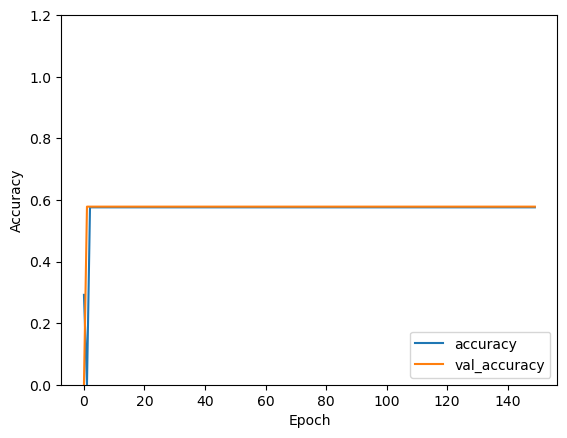

In [11]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

val_loss, val_acc = model.evaluate(input_val,  output_val, verbose=2)

4395/4395 - 6s - loss: 0.4368 - accuracy: 0.5782 - 6s/epoch - 1ms/step


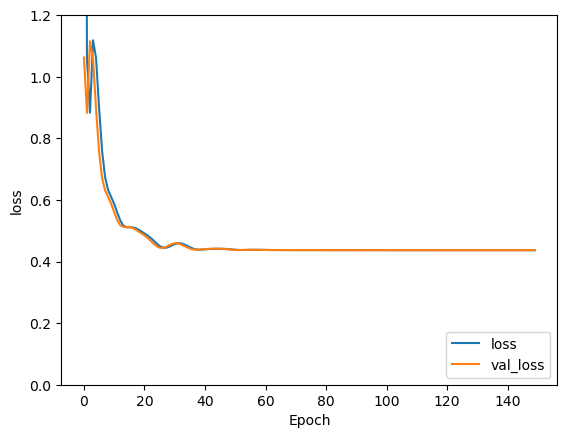

In [12]:
plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

val_loss, val_acc = model.evaluate(input_val,  output_val, verbose=2)

In [13]:
output_prediction = model.predict(input_train)
for i in range(0, len(output_prediction)):
    for j in range(0, output_col_num):
        output_prediction[i][j] = output_prediction[i][j]*output_norm_array[j]
        #a = 0

ML_result_df = pd.DataFrame(output_prediction, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

4395/4395 [==============================] - 4s 980us/step
writing to file : ML_FFA_sample/FFA_ML_result.dat


In [14]:
start_index = 0
end_index = 30
print(output_train[start_index:end_index]*output_norm_array)
print(output_prediction[start_index:end_index])

[[ 4.648807e-01 -0.000000e+00  7.694369e-02  4.238306e-02  9.990271e-01
   1.218828e-02]
 [ 3.062587e-01  0.000000e+00 -9.205985e-02  4.604268e-02  9.988910e-01
  -9.844949e-03]
 [ 4.771861e-01  0.000000e+00 -1.439235e-01  2.112240e-02  9.997732e-01
   2.717762e-03]
 [ 3.872492e-01  0.000000e+00  5.413478e-02  2.249127e-02  9.994710e-01
   2.349133e-02]
 [ 5.032575e-01  0.000000e+00 -6.474151e-02  2.102510e-02  9.997669e-01
   4.903513e-03]
 [ 4.613057e-01  0.000000e+00  5.090012e-02  4.150596e-02  9.988666e-01
   2.329613e-02]
 [ 3.337622e-01  0.000000e+00  9.805818e-02  1.517746e-02  9.998261e-01
   1.083545e-02]
 [ 4.278580e-01  0.000000e+00  1.688110e-01  1.610215e-02  9.998683e-01
   2.023298e-03]
 [ 0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
   0.000000e+00]
 [ 3.091407e-01  0.000000e+00 -7.397998e-02  1.723557e-02  9.997930e-01
   1.081182e-02]
 [ 3.089753e-01  0.000000e+00  2.305520e-02  1.750141e-02  9.997031e-01
   1.695114e-02]
 [ 4.375857e-01  0.00

140625
pred data
[[ 5.1798612e-01  7.6802876e-03 -2.7624839e-03  6.4798884e-02
   7.0624727e-01 -8.1981678e-05]
 [ 5.1868874e-01  9.0274792e-03 -2.6268535e-03  6.4811677e-02
   7.0682245e-01 -1.3309982e-04]
 [ 5.1797664e-01  6.7001563e-03 -2.7225786e-03  6.4782627e-02
   7.0633304e-01 -6.9858099e-05]
 ...
 [ 5.1624084e-01 -8.2642748e-04  6.1098998e-04  6.4819410e-02
   7.0322132e-01  2.0638443e-05]
 [ 5.1622593e-01 -3.0229182e-03  9.1521209e-04  6.4803183e-02
   7.0232433e-01  8.1135964e-05]
 [ 5.1687431e-01 -3.9961506e-03  1.8678373e-04  6.4810373e-02
   7.0281684e-01  8.0289581e-05]]
val data
[[ 0.1982683   0.          0.04134328  0.01906218  0.9995682   0.02236005]
 [ 0.2996506   0.         -0.2113335   0.04194485  0.9991152  -0.00307301]
 [ 0.2897762   0.          0.1956625   0.04833021  0.9987554   0.01231858]
 ...
 [ 1.199125    0.         -0.1792084   0.1519496   0.9882387  -0.01719233]
 [ 1.160653    0.          0.07060928  0.1373023   0.9905189   0.00451105]
 [ 0.9906251   0. 

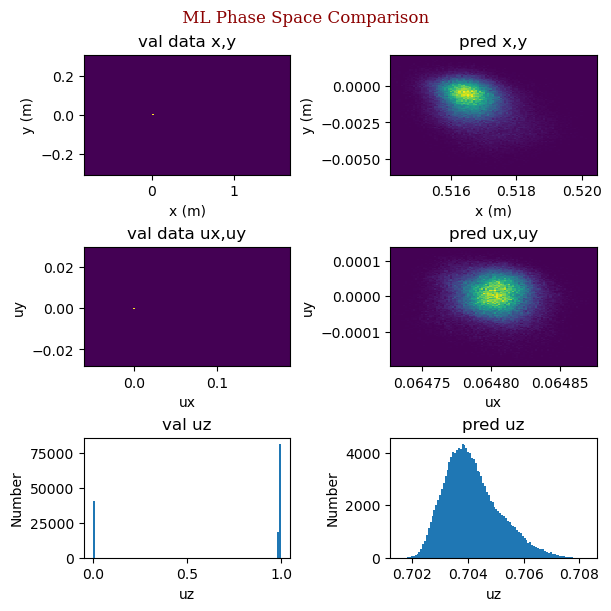

In [15]:
print(len(output_prediction))
print("pred data")
print(output_prediction)
print("val data")
print(output_val*output_norm_array)

unpack_output_val = output_val*output_norm_array

part_num = len(output_prediction)
#val_survive_index = []
    
unpack_output_val = unpack_output_val#[val_survive_index]
#phase_space_pred_survive = output_prediction[pred_survive_index]

#print("val surving particle num : "+str(len(val_survive_index)))
#+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")


fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(output_prediction[:,0], output_prediction[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(output_prediction[:,3], output_prediction[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('uz')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(output_prediction[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [16]:
#=================================================================================
#Advanced architecture with same data as above
#=================================================================================

In [17]:
fixfield_input = tf.keras.Input(shape=(9,),name="fixfield_input")

fixfield_parameters = tf.keras.Input(shape=(17,),name="fixfield_parameters")

x = tf.keras.layers.Dense(128)(fixfield_input)# phase space input

x = tf.keras.layers.LayerNormalization()(x)

p = tf.keras.layers.Dense(128, activation="tanh")(fixfield_parameters)
p = tf.keras.layers.Dense(128, activation="tanh")(p)

combined = tf.keras.layers.Concatenate()([x, p])
combined = tf.keras.layers.Dense(256, activation="tanh")(combined)
combined = tf.keras.layers.Dropout(0.1)(combined)
combined = tf.keras.layers.Dense(128, activation="tanh")(combined)

phase_space_output = tf.keras.layers.Dense(6,activation="linear",name="phase_space_output")(combined)# phase space output
survival_output = tf.keras.layers.Dense(1,activation="sigmoid",name="survival_output")(combined)# Binary classification

model_sep_in_out = tf.keras.models.Model(
    inputs=[fixfield_input, fixfield_parameters],
    outputs=[phase_space_output,survival_output]
)

In [18]:
#BinaryCrossentropy()  MeanSquaredError()  CosineSimilarity()  Huber()  KLDivergence  Poisson

model_sep_in_out.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss={
        "phase_space_output": tf.keras.losses.Huber(),
        "survival_output": tf.keras.losses.BinaryCrossentropy()
    },

    loss_weights={
        "phase_space_output": 1.0,
        "survival_output": 0.3
    },

    weighted_metrics={
        "phase_space_output": ["accuracy"],#mae
        "survival_output": ["accuracy"]
    }
)

model_sep_in_out.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 fixfield_input (InputLayer)    [(None, 9)]          0           []                               
                                                                                                  
 fixfield_parameters (InputLaye  [(None, 17)]        0           []                               
 r)                                                                                               
                                                                                                  
 dense_5 (Dense)                (None, 128)          1280        ['fixfield_input[0][0]']         
                                                                                                  
 dense_6 (Dense)                (None, 128)          2304        ['fixfield_parameters[0][0]']

In [19]:
#train the model
num_epochs = 500
#Not worried about memory or local minima
batchSize = len(input_train)

#Train on data
history = model_sep_in_out.fit(
    x={
        "fixfield_input": input_phase_space_train,
        "fixfield_parameters": input_para_train
    },

    y={
        "phase_space_output": output_train,
        "survival_output": output_lost_train
    },

    sample_weight={
        "phase_space_output": output_lost_train,
        "survival_output": np.ones(sample_part_num)
    },

    validation_data=({
        "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },

    {
        "phase_space_output": output_val,
        "survival_output": output_lost_val
    }#,

    #{"phase_space_output": output_lost_val,"survival_output": np.ones(sample_part_num)}#weight for validation data
    ),


    epochs=num_epochs,
    batch_size=batchSize
)

full_model_filename = 'FFA_sep_in_out_model'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model_sep_in_out.save(model_filename)

Epoch 1/500
1/1 [==============================] - 1s 1s/step - loss: 0.6676 - phase_space_output_loss: 0.3426 - survival_output_loss: 1.0831 - phase_space_output_accuracy: 0.0285 - survival_output_accuracy: 0.2992 - val_loss: 0.5228 - val_phase_space_output_loss: 0.3166 - val_survival_output_loss: 0.6872 - val_phase_space_output_accuracy: 0.1331 - val_survival_output_accuracy: 0.7039
Epoch 2/500
1/1 [==============================] - 0s 77ms/step - loss: 0.4005 - phase_space_output_loss: 0.1934 - survival_output_loss: 0.6902 - phase_space_output_accuracy: 0.4652 - survival_output_accuracy: 0.7008 - val_loss: 0.6044 - val_phase_space_output_loss: 0.3366 - val_survival_output_loss: 0.8926 - val_phase_space_output_accuracy: 0.5782 - val_survival_output_accuracy: 0.7039
Epoch 3/500
1/1 [==============================] - 0s 79ms/step - loss: 0.4193 - phase_space_output_loss: 0.1525 - survival_output_loss: 0.8894 - phase_space_output_accuracy: 0.8218 - survival_output_accuracy: 0.7008 - val

4395/4395 - 11s - loss: 0.1591 - phase_space_output_loss: 0.0235 - survival_output_loss: 0.4519 - phase_space_output_accuracy: 0.9452 - survival_output_accuracy: 0.8026 - 11s/epoch - 2ms/step


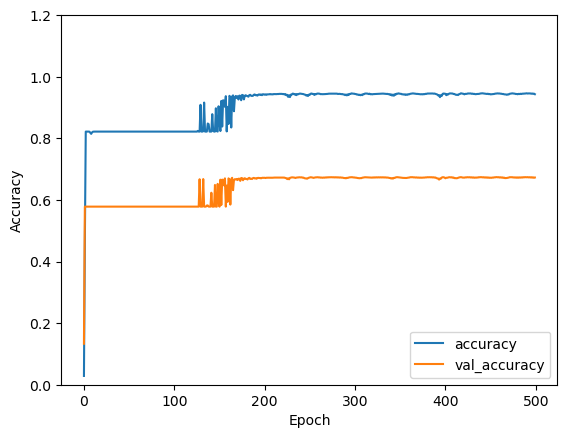

In [20]:
plt.plot(history.history['phase_space_output_accuracy'], label='accuracy')
plt.plot(history.history['val_phase_space_output_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

#val_loss_phase_space, val_loss_lost_part, val_acc_phase_space,  val_acc_lost_part
results = model_sep_in_out.evaluate(x={
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },
    y={
        "phase_space_output": output_val,
        "survival_output": output_lost_val
    },
   sample_weight={
        "phase_space_output": output_lost_val,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

4395/4395 - 11s - loss: 0.1591 - phase_space_output_loss: 0.0235 - survival_output_loss: 0.4519 - phase_space_output_accuracy: 0.9452 - survival_output_accuracy: 0.8026 - 11s/epoch - 3ms/step


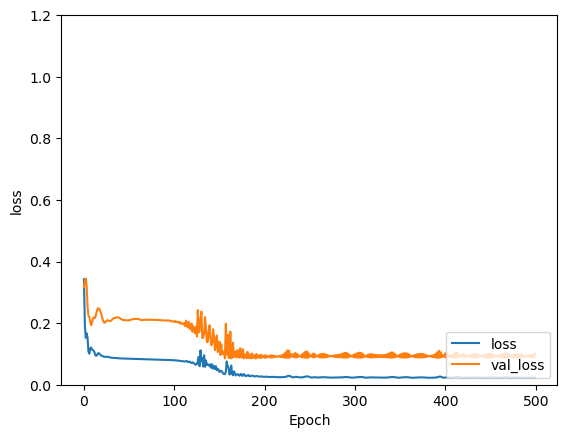

In [21]:
plt.plot(history.history['phase_space_output_loss'], label='loss')
plt.plot(history.history['val_phase_space_output_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

results = model_sep_in_out.evaluate(x={
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },
    y={
        "phase_space_output": output_val,
        "survival_output": output_lost_val
    },
   sample_weight={
        "phase_space_output": output_lost_val,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

In [22]:
output_sep_in_out_prediction = model_sep_in_out.predict({
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    })
phase_space_pred = output_sep_in_out_prediction[0]
part_lost_pred = output_sep_in_out_prediction[1].squeeze()
for i in range(0, len(output_prediction)):
    for j in range(0, output_col_num):
        phase_space_pred[i][j] = phase_space_pred[i][j]*output_norm_array[j]
        #a = 0

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_sep_in_out_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

4395/4395 [==============================] - 5s 1ms/step
writing to file : ML_FFA_sample/FFA_ML_sep_in_out_result.dat


pred data
[0.69072026 0.68823534 0.68752915 0.68651384 0.6922064  0.68087953
 0.6817032  0.68196976 0.6779877  0.6778627  0.67811376 0.6792408
 0.6804913  0.67796004 0.6828177  0.6771968  0.67739666 0.6817546
 0.6793339  0.67764574 0.6802558  0.6794468  0.6808306  0.6792927
 0.6826089  0.67964286 0.6811385  0.6808351  0.68059444 0.6810596 ]
val data
[1. 1. 0. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 1. 1. 1.
 1. 1. 1. 0. 1. 1.]
Within 140625 particles 70.39004444444444 % survival rate
Threshold value to have correct survival rate : 0.673131338816084 est_sruvive_rate 0.7039004444444443
correct survival rate at same_survive : 0.8533301525112977 lost rate 0.6536622266799109


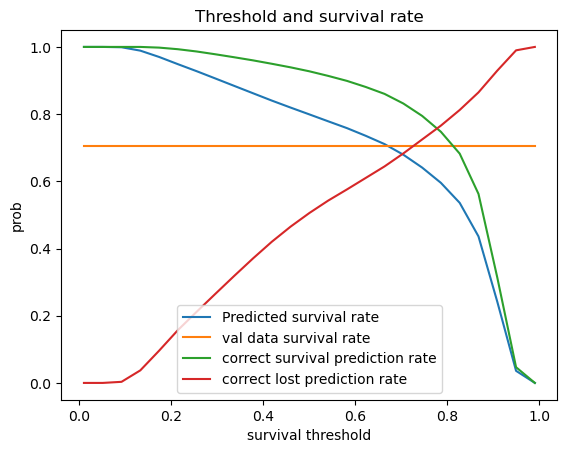

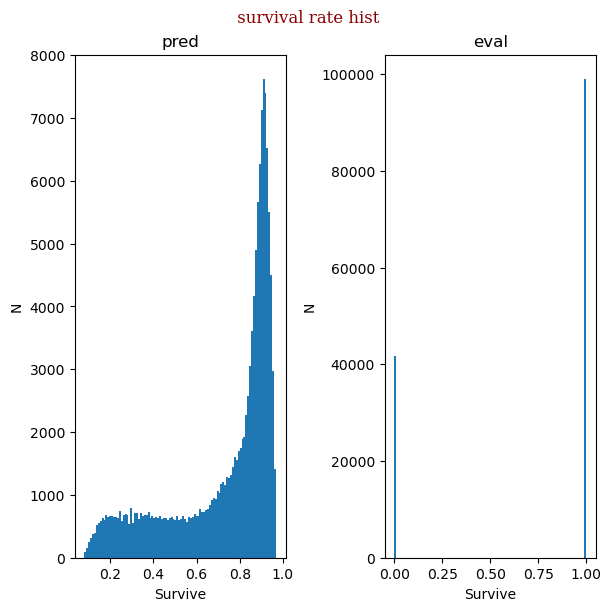

In [23]:
start_index = 270
end_index = 300
print("pred data")
print(part_lost_pred[start_index:end_index])
print("val data")
print(output_lost_val[start_index:end_index])

#calc total survival prob
thresh_num = 25
survive_thresh_lst = np.linspace(0.01,0.99,thresh_num)
pred_prob_lst = np.zeros(thresh_num)
val_prob_lst = np.zeros(thresh_num)
correct_sur_prob_lst = np.zeros(thresh_num)
correct_lost_prob_lst = np.zeros(thresh_num)

for thresh_index in range(0, thresh_num):
    survive_thresh = survive_thresh_lst[thresh_index]
    pred_prob = 0
    val_prob = 0
    correct_sur_prob = 0
    correct_lost_prob = 0
    part_num = len(part_lost_pred)
    for i in range(0, part_num):
        if part_lost_pred[i]>survive_thresh:
            pred_prob = pred_prob + 1
    
        if output_lost_val[i]>survive_thresh:
            val_prob = val_prob + 1
            if part_lost_pred[i]>survive_thresh:
                correct_sur_prob = correct_sur_prob + 1 #add when both val data and pred is surviving
        else:
            if part_lost_pred[i]<survive_thresh:
                correct_lost_prob = correct_lost_prob + 1 #add when both val data and pred is lost
    
    correct_sur_prob = correct_sur_prob/val_prob #devide by val data surviving particle number
    correct_lost_prob = correct_lost_prob/(part_num-val_prob) #devide by val data lost particle number
    pred_prob = pred_prob/part_num
    val_prob = val_prob/part_num

    correct_sur_prob_lst[thresh_index] = correct_sur_prob
    correct_lost_prob_lst[thresh_index] = correct_lost_prob
    pred_prob_lst[thresh_index] = pred_prob
    val_prob_lst[thresh_index] = val_prob

    #print("Threshold value for survival : "+str(survive_thresh))
    #print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate and "+str(pred_prob*100)+" % survival rate from prediction")
    #print(str(correct_sur_prob*100)+" % correct survival prediction and "+str(correct_lost_prob*100)+" % correct lost prediction")


same_survive_thresh, est_sruvive_rate = find_intercept(survive_thresh_lst, val_prob_lst, survive_thresh_lst, pred_prob_lst)

print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate")
print("Threshold value to have correct survival rate : "+str(same_survive_thresh)+" est_sruvive_rate "+str(est_sruvive_rate))

f_correct_sur_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_sur_prob_lst, kind='linear')
f_correct_lost_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_lost_prob_lst, kind='linear')
correct_sur_prob_same_survive_thresh = f_correct_sur_prob(same_survive_thresh)
correct_lost_prob_same_survive_thresh = f_correct_lost_prob(same_survive_thresh)

print("correct survival rate at same_survive : "+str(correct_sur_prob_same_survive_thresh)+" lost rate "+str(correct_lost_prob_same_survive_thresh))

plt.title('Threshold and survival rate')
plt.plot(survive_thresh_lst, pred_prob_lst, label='Predicted survival rate')
plt.plot(survive_thresh_lst, val_prob_lst, label='val data survival rate')
plt.plot(survive_thresh_lst, correct_sur_prob_lst, label='correct survival prediction rate')
plt.plot(survive_thresh_lst, correct_lost_prob_lst, label='correct lost prediction rate')

plt.xlabel("survival threshold")
plt.ylabel("prob")
plt.legend()
plt.show()

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " survival rate hist"

fig.suptitle(Ttl, fontdict=font)

axs[0].set_title('pred')
axs[0].hist(part_lost_pred, 100)
axs[0].set_xlabel('Survive')
axs[0].set_ylabel('N')


axs[1].set_title('eval')
axs[1].hist(output_lost_val, 100)
axs[1].set_xlabel('Survive')
axs[1].set_ylabel('N')

plt.show()


140625
pred data
[[ 7.8666282e-01 -1.5645247e-02 -7.4462313e-03  9.6137188e-02
   1.0055474e+00 -5.6101027e-05]
 [ 7.8989047e-01 -1.4542204e-02 -7.5772423e-03  9.6632607e-02
   1.0058713e+00 -6.8795627e-05]
 [ 7.9240334e-01 -1.4937741e-02 -6.4491648e-03  9.7116888e-02
   1.0055082e+00 -7.8430123e-05]
 ...
 [ 1.0257783e+00 -5.8089318e-03 -1.7475507e-03  1.2210135e-01
   1.0030446e+00  1.8332061e-05]
 [ 1.0258002e+00 -5.6180777e-03 -1.5224835e-03  1.2212595e-01
   1.0031236e+00  2.2403057e-05]
 [ 1.0261182e+00 -5.1144185e-03 -2.0892045e-03  1.2216241e-01
   1.0032634e+00  2.5616941e-05]]
val data
[[ 0.1982683   0.          0.04134328  0.01906218  0.9995682   0.02236005]
 [ 0.2996506   0.         -0.2113335   0.04194485  0.9991152  -0.00307301]
 [ 0.2897762   0.          0.1956625   0.04833021  0.9987554   0.01231858]
 ...
 [ 1.199125    0.         -0.1792084   0.1519496   0.9882387  -0.01719233]
 [ 1.160653    0.          0.07060928  0.1373023   0.9905189   0.00451105]
 [ 0.9906251   0. 

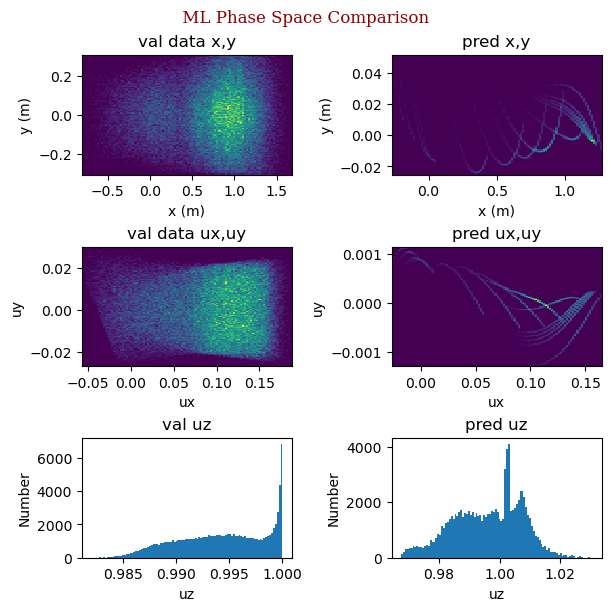

In [24]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
print(output_val*output_norm_array)

unpack_output_val = output_val*output_norm_array
part_num = len(part_lost_pred)
pred_survive_index = []
val_survive_index = []
same_survive_thresh
for i in range(0,part_num):
    if part_lost_pred[i]>same_survive_thresh:
        pred_survive_index.append(i)
    if output_lost_val[i]>same_survive_thresh:
        val_survive_index.append(i)
    
unpack_output_val = unpack_output_val[val_survive_index]
phase_space_pred_survive = phase_space_pred[pred_survive_index]

print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,3], phase_space_pred_survive[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('uz')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(phase_space_pred_survive[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [25]:
#=================================================================================
#Advanced architecture with delta value as data instead of raw values
#=================================================================================

In [26]:
#get only the phase space from input df columns for delta phase space calculation


input_phase_space_for_delta_calc_df = input_df[fixfield_phase_space_headers]
input_phase_space_for_delta_calc_np_lst = input_phase_space_for_delta_calc_df.to_numpy()

output_np_lst = output_df.to_numpy()
output_lost_lst = np.ones(len(output_df["x [m]"])) #list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

print("number of particles : "+str(len(output_df["x [m]"])))

#============================================================================================================
#put the read data into np array


input_delta_calc_train = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #input phase space for training data delta
output_delta_train = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #change of phase space instead of raw val

input_delta_calc_val = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #input phase space for val data delta
output_delta_val = np.zeros(sample_part_num*output_col_num).reshape((sample_part_num,output_col_num)) #change of phase space instead of raw val

FFA_parameter_norm = 200
Ptot_norm = 1e4
space_norm = 2

#create array for normalizing number in data to -1 ~ 1
input_norm_array = np.ones(input_col_num)
output_norm_array = np.ones(output_col_num)

for i in range(0, FFA_parameter_len):
    input_norm_array[i] = FFA_parameter_norm

for i in range(0, 3):
    input_norm_array[i+2+FFA_parameter_len] = space_norm
    output_norm_array[i] = space_norm

input_norm_array[5+FFA_parameter_len] = Ptot_norm
output_norm_array[3] = 0.1
output_norm_array[4] = 0.1
output_norm_array[5] = 0.1
#output_norm_array[5] = Ptot_norm

lost_count_train = 0
lost_count_val = 0
for i in range(0,sample_part_num):
    input_delta_calc_train[i] = input_phase_space_for_delta_calc_np_lst[2*i]
    input_delta_calc_val[i] = input_phase_space_for_delta_calc_np_lst[2*i+1]

    if (output_train[i][3]+output_train[i][4]+output_train[i][5])<1e-6:#lost particles have 0 phase space val. So sum of ux,uy,uz is 0 -> lost
        output_delta_train[i] = output_np_lst[2*i] #don't calc delta for lost particle
        lost_count_train = lost_count_train + 1
    else:
        output_delta_train[i] = output_np_lst[2*i] - input_delta_calc_train[i] #calc delta for surviving particle

    if (output_val[i][3]+output_val[i][4]+output_val[i][5])<1e-6:
        output_delta_val[i] = output_np_lst[2*i+1]
        lost_count_val = lost_count_val + 1
    else:
        output_delta_val[i] = output_np_lst[2*i+1] - input_delta_calc_val[i]

    
    

    #normalize numbers in array for ML
    

    for j in range(0, output_col_num):
        output_delta_train[i][j] = output_delta_train[i][j]/output_norm_array[j]
        output_delta_val[i][j] = output_delta_val[i][j]/output_norm_array[j]



print("output_delta_train")
print(output_delta_train)
print("lost_count_train : "+str(lost_count_train)+", lost_count_val : "+str(lost_count_val))
print(output_delta_val[4])
print(output_norm_array)
print("train particle num : "+str(len(input_train))+", val particle num : "+str(len(input_val))
      +", input column : "+str(len(input_train[0]))+",  output column : "+str(len(output_train[0])))

number of particles : 281250
output_delta_train
[[ 2.85619278e-01 -0.00000000e+00  6.57189573e-02  2.54632659e-01
  -7.56210359e-03  6.17432090e-04]
 [ 2.15790347e-01  0.00000000e+00 -5.51756398e-02  4.52142681e-01
  -1.05210646e-02  7.89785685e-03]
 [ 1.84537271e-01  0.00000000e+00 -9.13982614e-03  5.61345395e-02
  -8.26978825e-04  9.62109903e-02]
 ...
 [ 5.79997248e-01  0.00000000e+00 -1.18081825e-01  1.59155681e+00
  -1.21182074e-01 -1.77733867e-02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
   0.00000000e+00  0.00000000e+00]]
lost_count_train : 42077, lost_count_val : 41639
[ 0.12614254  0.          0.03358512  0.54595689 -0.00735459 -0.05653292]
[2.  2.  2.  0.1 0.1 0.1]
train particle num : 140625, val particle num : 140625, input column : 26,  output column : 6


In [27]:
fixfield_input = tf.keras.Input(shape=(9,),name="fixfield_input")# phase space input

fixfield_parameters = tf.keras.Input(shape=(17,),name="fixfield_parameters")

x = tf.keras.layers.Dense(128)(fixfield_input)
x = tf.keras.layers.LayerNormalization()(x)

p = tf.keras.layers.Dense(128, activation="tanh")(fixfield_parameters)
p = tf.keras.layers.Dense(128, activation="tanh")(p)

combined = tf.keras.layers.Concatenate()([x, p])
combined = tf.keras.layers.Dense(128, activation="tanh")(combined)
combined = tf.keras.layers.Dropout(0.1)(combined)
combined = tf.keras.layers.Dense(128, activation="tanh")(combined)

phase_space_output = tf.keras.layers.Dense(6,activation="linear",name="phase_space_delta_output")(combined)# phase space output
survival_output = tf.keras.layers.Dense(1,activation="sigmoid",name="survival_output")(combined)# Binary classification

model_sep_in_out_delta_calc = tf.keras.models.Model(
    inputs=[fixfield_input, fixfield_parameters],
    outputs=[phase_space_output,survival_output]
)

In [28]:
fixfield_input = tf.keras.Input(shape=(9,),name="fixfield_input")# phase space input

fixfield_parameters = tf.keras.Input(shape=(17,),name="fixfield_parameters")

x = tf.keras.layers.Dense(128)(fixfield_input)
x = tf.keras.layers.LayerNormalization()(x)

p = tf.keras.layers.Dense(128, activation="tanh")(fixfield_parameters)
p = tf.keras.layers.Dense(128, activation="tanh")(p)

combined = tf.keras.layers.Concatenate()([x, p])
combined = tf.keras.layers.Dense(128, activation="tanh")(combined)
combined = tf.keras.layers.Dropout(0.1)(combined)
combined = tf.keras.layers.Dense(64, activation="tanh")(combined)

x2 = tf.keras.layers.Dense(64, activation="tanh")(combined)
phase_space_output = tf.keras.layers.Dense(6,activation="linear",name="phase_space_delta_output")(x2)# phase space output

p2 = tf.keras.layers.Dense(64, activation="tanh")(combined)
survival_output = tf.keras.layers.Dense(1,activation="sigmoid",name="survival_output")(p2)# Binary classification

model_sep_in_out_delta_calc = tf.keras.models.Model(
    inputs=[fixfield_input, fixfield_parameters],
    outputs=[phase_space_output,survival_output]
)

In [29]:
#BinaryCrossentropy()  MeanSquaredError()  CosineSimilarity()  Huber()  KLDivergence  Poisson

model_sep_in_out_delta_calc.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss={
        "phase_space_delta_output": tf.keras.losses.Huber(),
        "survival_output": tf.keras.losses.BinaryCrossentropy()
    },

    loss_weights={
        "phase_space_delta_output": 1.0,
        "survival_output": 0.3
    },

    weighted_metrics={
        "phase_space_delta_output": ["accuracy"],#mae
        "survival_output": ["accuracy"]
    }
)

model_sep_in_out_delta_calc.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 fixfield_input (InputLayer)    [(None, 9)]          0           []                               
                                                                                                  
 fixfield_parameters (InputLaye  [(None, 17)]        0           []                               
 r)                                                                                               
                                                                                                  
 dense_15 (Dense)               (None, 128)          1280        ['fixfield_input[0][0]']         
                                                                                                  
 dense_16 (Dense)               (None, 128)          2304        ['fixfield_parameters[0][0]

In [30]:
#train the model
num_epochs = 300
#Not worried about memory or local minima
batchSize = len(input_train)

#Train on data
history = model_sep_in_out_delta_calc.fit(
    x={
        "fixfield_input": input_phase_space_train,
        "fixfield_parameters": input_para_train
    },

    y={
        "phase_space_delta_output": output_delta_train,
        "survival_output": output_lost_train
    },

    sample_weight={
        "phase_space_delta_output": output_lost_train,
        "survival_output": np.ones(sample_part_num)
    },

    validation_data=({
        "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },

    {
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val
    }#,

    #{"phase_space_output": output_lost_val,"survival_output": np.ones(sample_part_num)}#weight for validation data
    ),


    epochs=num_epochs,
    batch_size=batchSize
)

full_model_filename = 'FFA_sep_in_out_delta_calc_model'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model_sep_in_out_delta_calc.save(model_filename)

Epoch 1/300
1/1 [==============================] - 1s 1s/step - loss: 0.4702 - phase_space_delta_output_loss: 0.1802 - survival_output_loss: 0.9667 - phase_space_delta_output_accuracy: 0.1293 - survival_output_accuracy: 0.2992 - val_loss: 0.3116 - val_phase_space_delta_output_loss: 0.1033 - val_survival_output_loss: 0.6943 - val_phase_space_delta_output_accuracy: 0.0232 - val_survival_output_accuracy: 0.3212
Epoch 2/300
1/1 [==============================] - 0s 68ms/step - loss: 0.2781 - phase_space_delta_output_loss: 0.0693 - survival_output_loss: 0.6960 - phase_space_delta_output_accuracy: 0.3024 - survival_output_accuracy: 0.5052 - val_loss: 0.2973 - val_phase_space_delta_output_loss: 0.1148 - val_survival_output_loss: 0.6082 - val_phase_space_delta_output_accuracy: 0.6394 - val_survival_output_accuracy: 0.7039
Epoch 3/300
1/1 [==============================] - 0s 67ms/step - loss: 0.2369 - phase_space_delta_output_loss: 0.0527 - survival_output_loss: 0.6138 - phase_space_delta_outp

4395/4395 - 11s - loss: 0.1473 - phase_space_delta_output_loss: 0.0057 - survival_output_loss: 0.4720 - phase_space_delta_output_accuracy: 0.9035 - survival_output_accuracy: 0.7763 - 11s/epoch - 3ms/step


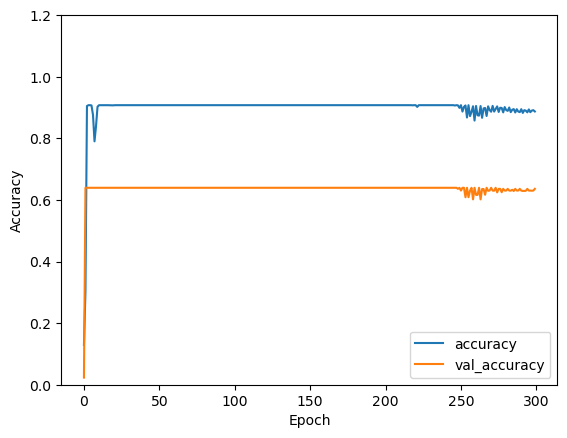

In [31]:
plt.plot(history.history['phase_space_delta_output_accuracy'], label='accuracy')
plt.plot(history.history['val_phase_space_delta_output_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

#val_loss_phase_space, val_loss_lost_part, val_acc_phase_space,  val_acc_lost_part
results = model_sep_in_out_delta_calc.evaluate(x={
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },
    y={
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val
    },
   sample_weight={
        "phase_space_delta_output": output_lost_val,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

4395/4395 - 11s - loss: 0.1473 - phase_space_delta_output_loss: 0.0057 - survival_output_loss: 0.4720 - phase_space_delta_output_accuracy: 0.9035 - survival_output_accuracy: 0.7763 - 11s/epoch - 3ms/step


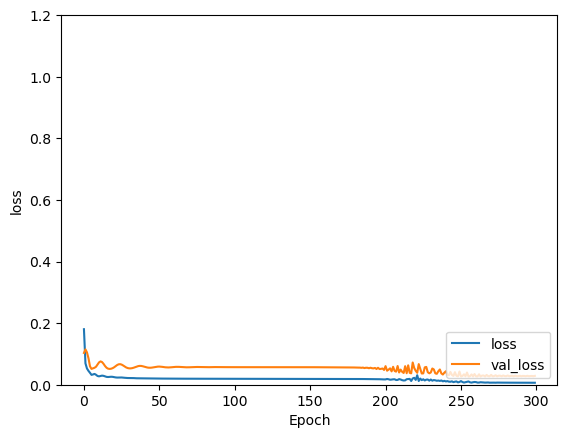

In [32]:
plt.plot(history.history['phase_space_delta_output_loss'], label='loss')
plt.plot(history.history['val_phase_space_delta_output_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

results = model_sep_in_out_delta_calc.evaluate(x={
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },
    y={
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val
    },
   sample_weight={
        "phase_space_delta_output": output_lost_val,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

In [33]:
output_sep_in_out_delta_calc_prediction = model_sep_in_out_delta_calc.predict({
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    })
phase_space_pred = output_sep_in_out_delta_calc_prediction[0]
part_lost_pred = output_sep_in_out_delta_calc_prediction[1].squeeze()
for i in range(0, len(output_prediction)):
    phase_space_pred[i] = phase_space_pred[i]*output_norm_array + input_delta_calc_val[i]
    #a = 0

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_sep_in_out_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

4395/4395 [==============================] - 6s 1ms/step
writing to file : ML_FFA_sample/FFA_ML_sep_in_out_result.dat


pred data
[0.78511006 0.7839729  0.7851857  0.7840244  0.7846831  0.7851152
 0.7839769  0.7851952  0.78510505 0.7850625  0.78401387 0.784408
 0.7849528  0.7841481  0.7849075  0.7851313  0.7840903  0.78513885
 0.7843067  0.78533137 0.78505474 0.7845143  0.78485894 0.7850605
 0.78465694 0.78226876 0.7822157  0.78128475 0.7822692  0.7821633 ]
val data
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]
Within 140625 particles 70.39004444444444 % survival rate
Threshold value to have correct survival rate : 0.5894527166486566 est_sruvive_rate 0.7039004444444446
correct survival rate at same_survive : 0.8438135017185694 lost rate 0.6284291660303516


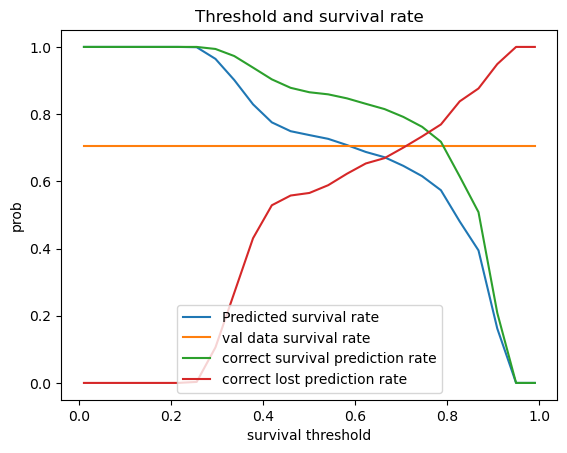

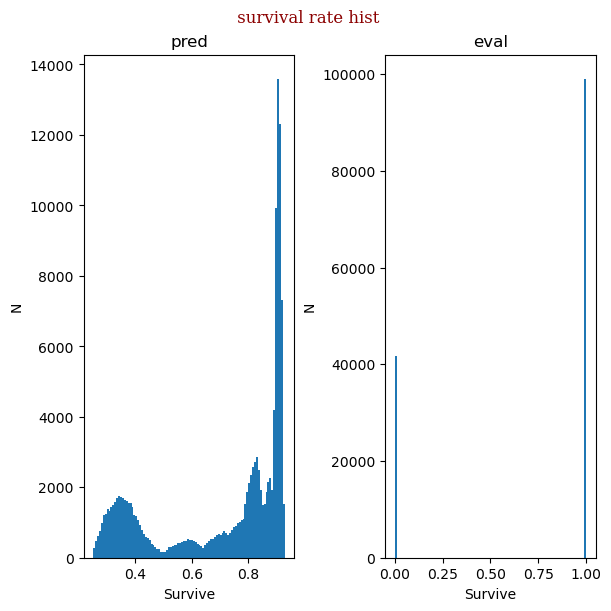

In [34]:
start_index = 2700
end_index = 2730
print("pred data")
print(part_lost_pred[start_index:end_index])
print("val data")
print(output_lost_val[start_index:end_index])

#calc total survival prob
thresh_num = 25
survive_thresh_lst = np.linspace(0.01,0.99,thresh_num)
pred_prob_lst = np.zeros(thresh_num)
val_prob_lst = np.zeros(thresh_num)
correct_sur_prob_lst = np.zeros(thresh_num)
correct_lost_prob_lst = np.zeros(thresh_num)

for thresh_index in range(0, thresh_num):
    survive_thresh = survive_thresh_lst[thresh_index]
    pred_prob = 0
    val_prob = 0
    correct_sur_prob = 0
    correct_lost_prob = 0
    part_num = len(part_lost_pred)
    for i in range(0, part_num):
        if part_lost_pred[i]>survive_thresh:
            pred_prob = pred_prob + 1
    
        if output_lost_val[i]>survive_thresh:
            val_prob = val_prob + 1
            if part_lost_pred[i]>survive_thresh:
                correct_sur_prob = correct_sur_prob + 1 #add when both val data and pred is surviving
        else:
            if part_lost_pred[i]<survive_thresh:
                correct_lost_prob = correct_lost_prob + 1 #add when both val data and pred is lost
    
    correct_sur_prob = correct_sur_prob/val_prob #devide by val data surviving particle number
    correct_lost_prob = correct_lost_prob/(part_num-val_prob) #devide by val data lost particle number
    pred_prob = pred_prob/part_num
    val_prob = val_prob/part_num

    correct_sur_prob_lst[thresh_index] = correct_sur_prob
    correct_lost_prob_lst[thresh_index] = correct_lost_prob
    pred_prob_lst[thresh_index] = pred_prob
    val_prob_lst[thresh_index] = val_prob

    #print("Threshold value for survival : "+str(survive_thresh))
    #print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate and "+str(pred_prob*100)+" % survival rate from prediction")
    #print(str(correct_sur_prob*100)+" % correct survival prediction and "+str(correct_lost_prob*100)+" % correct lost prediction")


same_survive_thresh, est_sruvive_rate = find_intercept(survive_thresh_lst, val_prob_lst, survive_thresh_lst, pred_prob_lst)

print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate")
print("Threshold value to have correct survival rate : "+str(same_survive_thresh)+" est_sruvive_rate "+str(est_sruvive_rate))

f_correct_sur_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_sur_prob_lst, kind='linear')
f_correct_lost_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_lost_prob_lst, kind='linear')
correct_sur_prob_same_survive_thresh = f_correct_sur_prob(same_survive_thresh)
correct_lost_prob_same_survive_thresh = f_correct_lost_prob(same_survive_thresh)

print("correct survival rate at same_survive : "+str(correct_sur_prob_same_survive_thresh)+" lost rate "+str(correct_lost_prob_same_survive_thresh))

plt.title('Threshold and survival rate')
plt.plot(survive_thresh_lst, pred_prob_lst, label='Predicted survival rate')
plt.plot(survive_thresh_lst, val_prob_lst, label='val data survival rate')
plt.plot(survive_thresh_lst, correct_sur_prob_lst, label='correct survival prediction rate')
plt.plot(survive_thresh_lst, correct_lost_prob_lst, label='correct lost prediction rate')

plt.xlabel("survival threshold")
plt.ylabel("prob")
plt.legend()
plt.show()

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " survival rate hist"

fig.suptitle(Ttl, fontdict=font)

axs[0].set_title('pred')
axs[0].hist(part_lost_pred, 100)
axs[0].set_xlabel('Survive')
axs[0].set_ylabel('N')


axs[1].set_title('eval')
axs[1].hist(output_lost_val, 100)
axs[1].set_xlabel('Survive')
axs[1].set_ylabel('N')

plt.show()


140625
pred data
[[ 0.85054976 -0.01362028 -0.2147266   0.0742883   0.9953465   0.01945535]
 [ 0.61422044 -0.01376303 -0.17641811  0.08801568  0.99558765 -0.00943874]
 [ 0.5636219  -0.01287564  0.01827666  0.08690241  0.99552053  0.01593346]
 ...
 [ 0.93048924 -0.01601752 -0.02021584  0.12127085  0.99266976 -0.01345826]
 [ 1.0943415  -0.01569011  0.00976006  0.10897692  0.992756    0.00450715]
 [ 0.97911394 -0.01584079  0.0480391   0.10145867  0.99265105 -0.00433882]]
val data
[[ 0.1982683   0.          0.04134328  0.01906218  0.9995682   0.02236005]
 [ 0.2996506   0.         -0.2113335   0.04194485  0.9991152  -0.00307301]
 [ 0.2897762   0.          0.1956625   0.04833021  0.9987554   0.01231858]
 ...
 [ 1.199125    0.         -0.1792084   0.1519496   0.9882387  -0.01719233]
 [ 1.160653    0.          0.07060928  0.1373023   0.9905189   0.00451105]
 [ 0.9906251   0.          0.00305214  0.140369    0.9900862  -0.00508592]]
val surving particle num : 98986, pred surving particle num : 

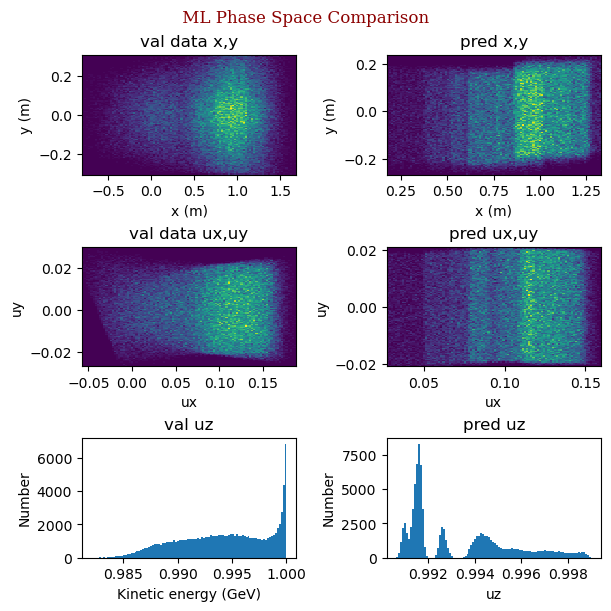

In [35]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
print(output_delta_val*output_norm_array+input_delta_calc_val)

unpack_output_val = output_delta_val*output_norm_array+input_delta_calc_val
part_num = len(part_lost_pred)
pred_survive_index = []
val_survive_index = []
same_survive_thresh
for i in range(0,part_num):
    if part_lost_pred[i]>same_survive_thresh:
        pred_survive_index.append(i)
    if output_lost_val[i]>same_survive_thresh:
        val_survive_index.append(i)
    
unpack_output_val = unpack_output_val[val_survive_index]
phase_space_pred_survive = phase_space_pred[pred_survive_index]

print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,3], phase_space_pred_survive[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('Kinetic energy (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(phase_space_pred_survive[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [36]:
#=================================================================================
#Advanced architecture with custom loss function
#=================================================================================

In [37]:
#tf.abs   tf.minimum    tf.square    tf.reduce_mean

def huber_loss(y_true, y_pred, delta=1.0):
    """
    Calculates the loss between y_true and y_pred.
    
    Returns:
    A tf.Tensor containing the loss values for each sample.
    shape = [batch_size, d0, .. dN-1]
    """
    y_true = tf.cast(y_true, dtype=y_pred.dtype) # Ensure types match
    error = y_true - y_pred
    abs_error = tf.abs(error)
    quadratic = tf.minimum(abs_error, delta)
    linear = abs_error - quadratic
    return 0.5 * tf.square(quadratic) + delta * linear


class custom_loss(tf.keras.losses.Loss):

    def __init__(self, lamb=1.0, norm_err=1.0,
                   reduction=tf.keras.losses.Reduction.SUM_OVER_BATCH_SIZE,
                   name='custom_loss'):
        super().__init__(reduction=reduction, name=name)
        self.lamb = lamb
        self.norm_err = norm_err

    def call(self, y_true, y_pred):

        # y_true contains:
        # first 3 values = x, y, z
        # last 3 values = ux, uy, uz
        #y is the beam axis

        y_true = tf.cast(y_true, dtype=y_pred.dtype) # Ensure types match

        space_true = y_true[:, :3]
        unit_vec_true = y_true[:, 3:]

        space_pred = y_pred[:, :3]
        unit_vec_pred = y_pred[:, 3:]

        space_error = space_true - space_pred
        unit_vec_error = unit_vec_true - unit_vec_pred

        unit_vec_norm = tf.reduce_sum(tf.square(unit_vec_pred), 1) #norm of the predicted unit vector
        unit_vec_norm_error = (1-unit_vec_norm) #unit vec should have magnitude of 1
        abs_unit_vec_norm_error = tf.abs(unit_vec_norm_error)
        unit_vec_quadratic = tf.minimum(abs_unit_vec_norm_error, self.lamb)
        unit_vec_linear = abs_unit_vec_norm_error - unit_vec_quadratic
        unit_vec_huber_loss = 0.5 * tf.square(unit_vec_quadratic) + self.lamb * unit_vec_linear

        error = y_true - y_pred
        abs_error = tf.abs(error)
        quadratic = tf.minimum(abs_error, self.lamb)
        linear = abs_error - quadratic
        huber_loss = 0.5 * tf.square(quadratic) + self.lamb * linear
        #tf.reduce_mean(tf.square(space_error) + self.lamb*tf.square(unit_vec_error))
        return huber_loss + self.norm_err * tf.reduce_mean(unit_vec_huber_loss)

In [38]:
test_ur_vec = np.array([[0.1,0.95,0.1], [0.09,0.95,0.11], [0.12,0.93,0.1], [0.089,0.97,0.078], [0.15,0.91,0.17]])
test_norm = tf.reduce_sum(tf.square(test_ur_vec), 1)
print(tf.square(1-test_norm))

tf.Tensor([0.00600625 0.00597529 0.01225449 0.00203356 0.01452025], shape=(5,), dtype=float64)


In [39]:
fixfield_input = tf.keras.Input(shape=(9,),name="fixfield_input")# phase space input

fixfield_parameters = tf.keras.Input(shape=(17,),name="fixfield_parameters")

x = tf.keras.layers.Dense(128)(fixfield_input)
x = tf.keras.layers.LayerNormalization()(x)

p = tf.keras.layers.Dense(128, activation="tanh")(fixfield_parameters)
p = tf.keras.layers.Dense(128, activation="tanh")(p)

combined = tf.keras.layers.Concatenate()([x, p])
combined = tf.keras.layers.Dense(128, activation="tanh")(combined)
combined = tf.keras.layers.Dropout(0.1)(combined)
combined = tf.keras.layers.Dense(128, activation="tanh")(combined)

phase_space_output = tf.keras.layers.Dense(6,activation="linear",name="phase_space_delta_output")(combined)# phase space output

survival_output = tf.keras.layers.Dense(1,activation="sigmoid",name="survival_output")(combined)# Binary classification

model_sep_in_out_delta_calc_custom_loss = tf.keras.models.Model(
    inputs=[fixfield_input, fixfield_parameters],
    outputs=[phase_space_output,survival_output]
)

In [40]:
#BinaryCrossentropy()  MeanSquaredError()  CosineSimilarity()  Huber()  KLDivergence  Poisson

model_sep_in_out_delta_calc_custom_loss.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),

    loss={
        "phase_space_delta_output": custom_loss(lamb=0.7, norm_err=0.05),#tf.keras.losses.Huber(),#
        "survival_output": tf.keras.losses.BinaryCrossentropy()
    },

    loss_weights={
        "phase_space_delta_output": 1.0,
        "survival_output": 0.3
    },

    weighted_metrics={
        "phase_space_delta_output": ["accuracy"],#mae
        "survival_output": ["accuracy"]
    }
)

model_sep_in_out_delta_calc_custom_loss.summary()

Model: "model_3"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 fixfield_input (InputLayer)    [(None, 9)]          0           []                               
                                                                                                  
 fixfield_parameters (InputLaye  [(None, 17)]        0           []                               
 r)                                                                                               
                                                                                                  
 dense_22 (Dense)               (None, 128)          1280        ['fixfield_input[0][0]']         
                                                                                                  
 dense_23 (Dense)               (None, 128)          2304        ['fixfield_parameters[0][0]

In [51]:

#train the model
num_epochs = 2400
#Not worried about memory or local minima
batchSize = len(input_phase_space_train)
print("batchSize : "+str(batchSize))

tf.print("y_true:", tf.shape(output_delta_train))
tf.print("y_pred:", tf.shape(output_delta_val))

#Train on data
history = model_sep_in_out_delta_calc_custom_loss.fit(
    x={
        "fixfield_input": input_phase_space_train,
        "fixfield_parameters": input_para_train
    },

    y={
        "phase_space_delta_output": output_delta_train,
        "survival_output": output_lost_train
    },

    sample_weight={
        "phase_space_delta_output": output_lost_train,
        "survival_output": np.ones(sample_part_num)
    },

    validation_data=({
        "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },

    {
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val
    }#,

    #{"phase_space_output": output_lost_val,"survival_output": np.ones(sample_part_num)}#weight for validation data
    ),


    epochs=num_epochs,
    batch_size=batchSize
)

full_model_filename = 'FFA_sep_in_out_delta_calc_model_custom_loss'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model_sep_in_out_delta_calc_custom_loss.save(model_filename)

batchSize : 140625
y_true: [140625 6]
y_pred: [140625 6]
Epoch 1/2400
1/1 [==============================] - 0s 470ms/step - loss: 0.1463 - phase_space_delta_output_loss: 0.0102 - survival_output_loss: 0.4534 - phase_space_delta_output_accuracy: 0.9067 - survival_output_accuracy: 0.8017 - val_loss: 0.1720 - val_phase_space_delta_output_loss: 0.0373 - val_survival_output_loss: 0.4488 - val_phase_space_delta_output_accuracy: 0.6399 - val_survival_output_accuracy: 0.8037
Epoch 2/2400
1/1 [==============================] - 0s 58ms/step - loss: 0.1465 - phase_space_delta_output_loss: 0.0102 - survival_output_loss: 0.4540 - phase_space_delta_output_accuracy: 0.9078 - survival_output_accuracy: 0.8013 - val_loss: 0.1718 - val_phase_space_delta_output_loss: 0.0370 - val_survival_output_loss: 0.4492 - val_phase_space_delta_output_accuracy: 0.6394 - val_survival_output_accuracy: 0.8039
Epoch 3/2400
1/1 [==============================] - 0s 58ms/step - loss: 0.1464 - phase_space_delta_output_loss:

4395/4395 - 13s - loss: 0.1403 - phase_space_delta_output_loss: 0.0096 - survival_output_loss: 0.4357 - phase_space_delta_output_accuracy: 0.9084 - survival_output_accuracy: 0.8133 - 13s/epoch - 3ms/step


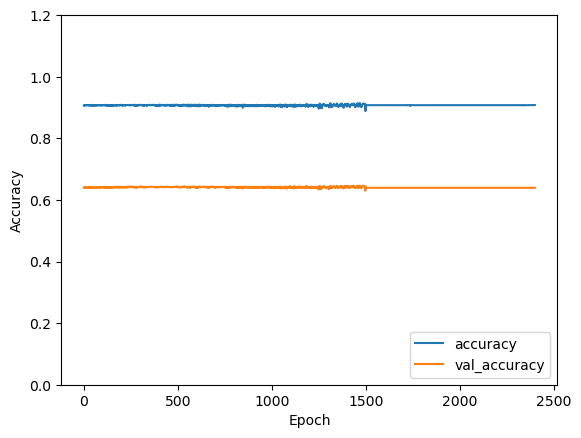

In [52]:
plt.plot(history.history['phase_space_delta_output_accuracy'], label='accuracy')
plt.plot(history.history['val_phase_space_delta_output_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

#val_loss_phase_space, val_loss_lost_part, val_acc_phase_space,  val_acc_lost_part
results = model_sep_in_out_delta_calc_custom_loss.evaluate(x={
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },
    y={
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val
    },
   sample_weight={
        "phase_space_delta_output": output_lost_val,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

4395/4395 - 12s - loss: 0.1403 - phase_space_delta_output_loss: 0.0096 - survival_output_loss: 0.4357 - phase_space_delta_output_accuracy: 0.9084 - survival_output_accuracy: 0.8133 - 12s/epoch - 3ms/step


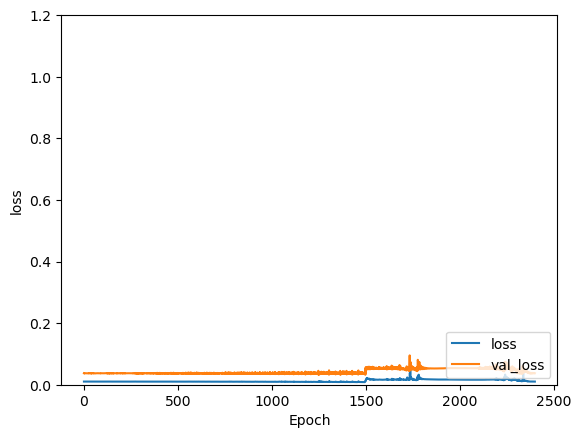

In [53]:
plt.plot(history.history['phase_space_delta_output_loss'], label='loss')
plt.plot(history.history['val_phase_space_delta_output_loss'], label = 'val_loss')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.ylim([0, 1.2])
plt.legend(loc='lower right')

results = model_sep_in_out_delta_calc_custom_loss.evaluate(x={
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    },
    y={
        "phase_space_delta_output": output_delta_val,
        "survival_output": output_lost_val
    },
   sample_weight={
        "phase_space_delta_output": output_lost_val,
        "survival_output": np.ones(sample_part_num)
    }, verbose=2)

In [54]:
output_sep_in_out_delta_calc_prediction = model_sep_in_out_delta_calc_custom_loss.predict({
       "fixfield_input": input_phase_space_val,
        "fixfield_parameters": input_para_val
    })
phase_space_pred = output_sep_in_out_delta_calc_prediction[0]
part_lost_pred = output_sep_in_out_delta_calc_prediction[1].squeeze()
for i in range(0, len(output_prediction)):
    phase_space_pred[i] = phase_space_pred[i]*output_norm_array + input_delta_calc_val[i]
    #a = 0

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_sep_in_out_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

4395/4395 [==============================] - 6s 1ms/step
writing to file : ML_FFA_sample/FFA_ML_sep_in_out_result.dat


pred data
[0.7968781  0.79205155 0.8022305  0.7895904  0.80024546 0.80256766
 0.7820179  0.8002754  0.7991596  0.7900427  0.79644614 0.79043204
 0.7987731  0.7868692  0.79538256 0.7999424  0.7934543  0.80476856
 0.79633963 0.80100393 0.7902328  0.79800546 0.80946654 0.79044265
 0.7975108  0.78865707 0.78805    0.7908977  0.78286076 0.77495885]
val data
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 1. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]
Within 140625 particles 70.39004444444444 % survival rate
Threshold value to have correct survival rate : 0.5894527166486566 est_sruvive_rate 0.7039004444444446
correct survival rate at same_survive : 0.8640589999662975 lost rate 0.6609288444829853


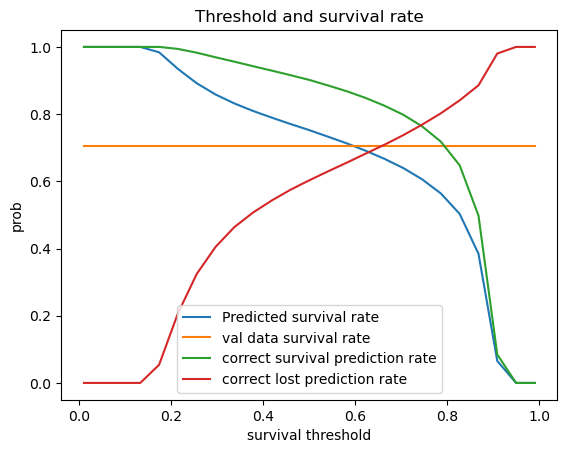

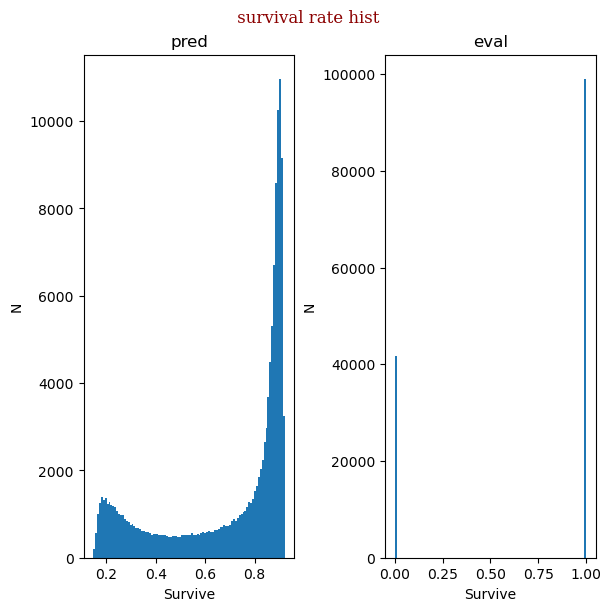

In [55]:
start_index = 2700
end_index = 2730
print("pred data")
print(part_lost_pred[start_index:end_index])
print("val data")
print(output_lost_val[start_index:end_index])

#calc total survival prob
thresh_num = 25
survive_thresh_lst = np.linspace(0.01,0.99,thresh_num)
pred_prob_lst = np.zeros(thresh_num)
val_prob_lst = np.zeros(thresh_num)
correct_sur_prob_lst = np.zeros(thresh_num)
correct_lost_prob_lst = np.zeros(thresh_num)

for thresh_index in range(0, thresh_num):
    survive_thresh = survive_thresh_lst[thresh_index]
    pred_prob = 0
    val_prob = 0
    correct_sur_prob = 0
    correct_lost_prob = 0
    part_num = len(part_lost_pred)
    for i in range(0, part_num):
        if part_lost_pred[i]>survive_thresh:
            pred_prob = pred_prob + 1
    
        if output_lost_val[i]>survive_thresh:
            val_prob = val_prob + 1
            if part_lost_pred[i]>survive_thresh:
                correct_sur_prob = correct_sur_prob + 1 #add when both val data and pred is surviving
        else:
            if part_lost_pred[i]<survive_thresh:
                correct_lost_prob = correct_lost_prob + 1 #add when both val data and pred is lost
    
    correct_sur_prob = correct_sur_prob/val_prob #devide by val data surviving particle number
    correct_lost_prob = correct_lost_prob/(part_num-val_prob) #devide by val data lost particle number
    pred_prob = pred_prob/part_num
    val_prob = val_prob/part_num

    correct_sur_prob_lst[thresh_index] = correct_sur_prob
    correct_lost_prob_lst[thresh_index] = correct_lost_prob
    pred_prob_lst[thresh_index] = pred_prob
    val_prob_lst[thresh_index] = val_prob

    #print("Threshold value for survival : "+str(survive_thresh))
    #print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate and "+str(pred_prob*100)+" % survival rate from prediction")
    #print(str(correct_sur_prob*100)+" % correct survival prediction and "+str(correct_lost_prob*100)+" % correct lost prediction")


#same_survive_thresh, est_sruvive_rate = find_intercept(survive_thresh_lst, val_prob_lst, survive_thresh_lst, pred_prob_lst)

print("Within "+str(part_num)+" particles "+str(val_prob*100)+" % survival rate")
print("Threshold value to have correct survival rate : "+str(same_survive_thresh)+" est_sruvive_rate "+str(est_sruvive_rate))

f_correct_sur_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_sur_prob_lst, kind='linear')
f_correct_lost_prob = scipy.interpolate.interp1d(survive_thresh_lst, correct_lost_prob_lst, kind='linear')
correct_sur_prob_same_survive_thresh = f_correct_sur_prob(same_survive_thresh)
correct_lost_prob_same_survive_thresh = f_correct_lost_prob(same_survive_thresh)

print("correct survival rate at same_survive : "+str(correct_sur_prob_same_survive_thresh)+" lost rate "+str(correct_lost_prob_same_survive_thresh))

plt.title('Threshold and survival rate')
plt.plot(survive_thresh_lst, pred_prob_lst, label='Predicted survival rate')
plt.plot(survive_thresh_lst, val_prob_lst, label='val data survival rate')
plt.plot(survive_thresh_lst, correct_sur_prob_lst, label='correct survival prediction rate')
plt.plot(survive_thresh_lst, correct_lost_prob_lst, label='correct lost prediction rate')

plt.xlabel("survival threshold")
plt.ylabel("prob")
plt.legend()
plt.show()

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " survival rate hist"

fig.suptitle(Ttl, fontdict=font)

axs[0].set_title('pred')
axs[0].hist(part_lost_pred, 100)
axs[0].set_xlabel('Survive')
axs[0].set_ylabel('N')


axs[1].set_title('eval')
axs[1].hist(output_lost_val, 100)
axs[1].set_xlabel('Survive')
axs[1].set_ylabel('N')

plt.show()


140625
pred data
[[ 0.7126431   0.02699101 -0.1636508   0.06778787  0.9941021   0.01924692]
 [ 0.47397625  0.02632329 -0.12621664  0.08132418  0.9944146  -0.00967181]
 [ 0.4332252   0.02724591  0.06871028  0.08091711  0.9941566   0.01579561]
 ...
 [ 0.9432643   0.01470188  0.00374826  0.11421875  0.9932919  -0.0148784 ]
 [ 1.1123372   0.01491854  0.03311685  0.10236625  0.9932949   0.00312501]
 [ 0.9943299   0.0151293   0.07172253  0.09464193  0.9932132  -0.00575137]]
val data
[[ 0.1982683   0.          0.04134328  0.01906218  0.9995682   0.02236005]
 [ 0.2996506   0.         -0.2113335   0.04194485  0.9991152  -0.00307301]
 [ 0.2897762   0.          0.1956625   0.04833021  0.9987554   0.01231858]
 ...
 [ 1.199125    0.         -0.1792084   0.1519496   0.9882387  -0.01719233]
 [ 1.160653    0.          0.07060928  0.1373023   0.9905189   0.00451105]
 [ 0.9906251   0.          0.00305214  0.140369    0.9900862  -0.00508592]]
val surving particle num : 98986, pred surving particle num : 

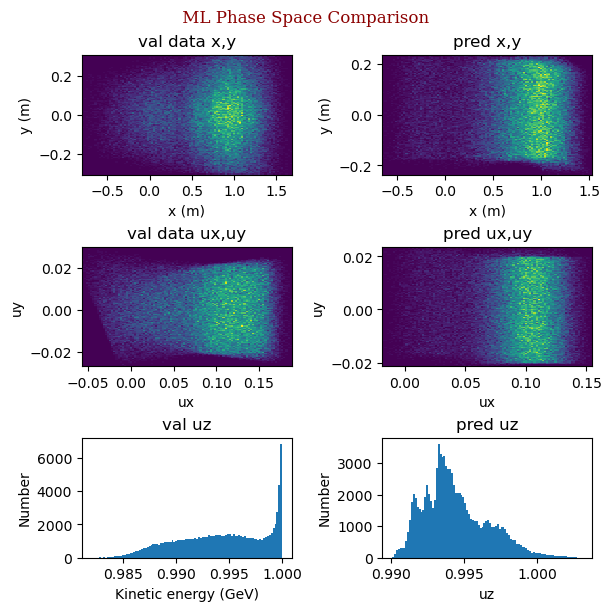

In [56]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
print(output_delta_val*output_norm_array+input_delta_calc_val)

unpack_output_val = output_delta_val*output_norm_array+input_delta_calc_val
part_num = len(part_lost_pred)
pred_survive_index = []
val_survive_index = []
#same_survive_thresh = 0.70074
for i in range(0,part_num):
    if part_lost_pred[i]>same_survive_thresh:
        pred_survive_index.append(i)
    if output_lost_val[i]>same_survive_thresh:
        val_survive_index.append(i)
    
unpack_output_val = unpack_output_val[val_survive_index]
phase_space_pred_survive = phase_space_pred[pred_survive_index]

print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,3], phase_space_pred_survive[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('Kinetic energy (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(phase_space_pred_survive[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [47]:
#=================================================================================
#Transfer matrix FFA ML
#takes FFA parameters as input and calculates loss with particle data
#=================================================================================

In [48]:
class TransferMatrixModel(keras.Model):

    def __init__(self):
        super().__init__()

        self.network = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(17,)),

            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),

            # Output 36 matrix elements
            tf.keras.layers.Dense(36)
        ])

    def call(self, field):

        # field:
        # (N_fields, 17)

        matrix_elements = self.network(field)

        # matrix_elements:
        # (N_fields, 36)

        M = tf.reshape(
            matrix_elements,
            (-1, 6, 6)
        )

        # M:
        # (N_fields, 6, 6)

        return M

In [49]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

@tf.function
def train_step(field, z_before, z_after):

    with tf.GradientTape() as tape:

        phase_space_pred, M = model(
            field,
            phase_space_before
        )

        loss = tf.reduce_mean(tf.square( phase_space_pred - phase_space_after))

    gradients = tape.gradient(loss, model.trainable_variables)

    optimizer.apply_gradients(
        zip(
            gradients,
            model.trainable_variables
        )
    )

    return loss

In [50]:
#train the model
num_epochs = 1200
#Not worried about memory or local minima
batchSize = len(input_phase_space_train)

for epoch in range(num_epochs):

    loss = train_step(
        field,
        particles_before,
        particles_after
    )

    if epoch % 100 == 0:
        print(
            f"Epoch {epoch}: loss = {loss.numpy()}"
        )

NameError: name 'field' is not defined